In [104]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-
"""
Created on Mon Nov 23 11:39:44 2020

@author: berar
"""
import numpy as np
class GridWorld:
    def __init__(self, grid_size=4, discount=1., policy=None):
        self.grid_size = grid_size
        self.terminal_states = [0, grid_size*grid_size-1]
        self.states = np.arange(grid_size*grid_size)
        self.actions = ['UP', 'RIGHT', 'DOWN', 'LEFT']
        self.discount = discount
        self.policy = policy if policy is not None else self.uniform_policy()
        self.P = self.get_transition_matrix()
        
    def next_state(self, state, action):
        i,j = np.unravel_index(state, (self.grid_size, self.grid_size))
        if action == 'UP':
            i = np.maximum(0,i-1)
        elif action == 'DOWN':
            i = np.minimum(i+1,self.grid_size-1)
        elif action == 'RIGHT':
            j = np.minimum(j+1,self.grid_size-1)
        elif action == 'LEFT':
            j = np.maximum(0,j-1)    
        new_state = np.ravel_multi_index((i,j), (self.grid_size, self.grid_size))
        return new_state
    
    def is_done(self, state):
        return state in self.terminal_states

    def get_transition_matrix(self):
        P = {}
        for s in range(len(self.states)):
            P[s] = {a : () for a in self.actions}
            if s in self.terminal_states:
                # if terminal state, stay where you are
                # instead of next_state
                reward = 0.
                for action in self.actions:
                    P[s][action] = (s, reward, True)
            else:
                # transition
                reward = -1.
                for action in self.actions:
                    next_s = self.next_state(s, action)
                    P[s][action] = (next_s,reward,self.is_done(next_s))
        return P

    def uniform_policy(self):
        policy = {}
        for s in range(len(self.states)):
            policy[s] = {a: 1/len(self.actions) for a in self.actions}
        return policy

    def generate_P_s_s(self, P):
        K = len(P)
        P_ss = np.zeros((K, K))
        for state in P:
            if all([P[state][a][1] == 0 for a in self.actions]):
                # on ignore les états terminal
                continue
            for action, v in P[state].items():
                # print(k, v)
                P_ss[state, v[0]] += self.policy[state][action]
        return P_ss

    def generate_r_pi(self, P, uniform_policy):
        """La recompense rpi(s) """
        K = len(P)
        r_pi = np.zeros(K)
        for i in range(K):
            if all([P[i][a][1] == 0 for a in self.actions]):
                # on ignore les états terminal
                continue
            for action, v in P[i].items():
                r_pi[i] += self.policy[i][action] * v[1]
        return r_pi

    def generate_pi_a_s(self, P, uniform_policy):
        """La politique pi(a|s) """
        K = len(P)
        pi_a_s = np.zeros((K, len(self.actions)))
        for i in range(K):
            if all([P[i][a][1] == 0 for a in self.actions]):
                # on ignore les états terminal
                continue
            for j, action in enumerate(self.actions):
                pi_a_s[i, j] = self.policy[i][action]
        return pi_a_s


In [105]:
grid_4 = GridWorld(grid_size=4, discount=1., policy=None)
P_ss = grid_4.generate_P_s_s(grid_4.P)
P = grid_4.P
r_pi = grid_4.generate_r_pi(grid_4.P, grid_4.policy)
pi_a_s = grid_4.generate_pi_a_s(grid_4.P, grid_4.policy)


# Policy Evaluation

In [106]:
import numpy as np



def policy_evalution(P_ss, r_pi, states, discount=1):


    v = np.zeros(len(states))
    while True:
        delta = np.zeros(len(states))
        vs = v.copy()
        for s in range(len(states)):
            v[s] = r_pi[s] + discount * P_ss[s] @ vs
            delta[s] = np.abs(v[s] - vs[s])
        if np.max(delta) < 1e-6:
            break
    return v

policy_evalution(P_ss, r_pi, grid_4.states, discount=1)
            

array([  0.        , -13.99998982, -19.99998491, -21.99998311,
       -13.99998982, -17.9999867 , -19.99998501, -19.99998491,
       -19.99998491, -19.99998501, -17.9999867 , -13.99998982,
       -21.99998311, -19.99998491, -13.99998982,   0.        ])

In [107]:



def policy_evalution_matrix(P_ss, r_pi,  states, discount=1):
    v = np.zeros(len(states))
   
    while True:
        delta = np.zeros(len(states))
        vs = v.copy()
        v = r_pi + discount * P_ss @ vs
        delta = np.abs(v - vs)
        if np.max(delta) < 1e-6:
            break
    return v

policy_evalution_matrix(P_ss, r_pi, grid_4.states, discount=1)

array([  0.        , -13.99998982, -19.99998491, -21.99998311,
       -13.99998982, -17.9999867 , -19.99998501, -19.99998491,
       -19.99998491, -19.99998501, -17.9999867 , -13.99998982,
       -21.99998311, -19.99998491, -13.99998982,   0.        ])

In [108]:
def policy_evaluation_linear(P_ss, r_pi, states, discount=1):
    """Compute the value function for a given policy using linear algebra."""
    I = np.eye(len(states))
    v = np.linalg.solve(I - discount * P_ss, r_pi)
    return v

v = policy_evaluation_linear(P_ss, r_pi, grid_4.states, discount=1)
v

array([  0., -14., -20., -22., -14., -18., -20., -20., -20., -20., -18.,
       -14., -22., -20., -14.,   0.])

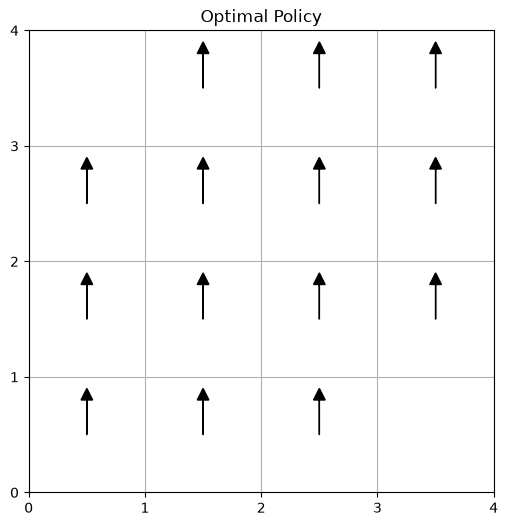

# policy  iteration

In [112]:
def policy_improvement(P, pi_a_s, v, states, actions, discount):
    new_pi_a_s = np.zeros_like(pi_a_s)
    for s in range(len(states)):
        if all([P[s][a][1] == 0 for a in actions]):
            continue
        q_values = np.zeros(len(actions))
        for j, action in enumerate(actions):
            next_s, reward, done = P[s][action]
            q_values[j] = reward + discount * v[next_s]
        best_action = np.argmax(q_values)
        new_pi_a_s[s] = np.eye(len(actions))[best_action]
    return new_pi_a_s




def policy_iteration(P_ss, P, r_pi, pi_a_s, states, actions, discount=1):
    v = np.zeros(P_ss.shape[0])
    policy_stable = False
    while not policy_stable:
        v = policy_evalution(P_ss, r_pi, states, discount=1)
        new_pi_a_s = policy_improvement(P, pi_a_s, v, states, actions,   discount)
        policy_stable = np.array_equal(new_pi_a_s, pi_a_s)
        pi_a_s = new_pi_a_s
        if policy_stable:
            break
    return v, pi_a_s
    
v, pi_a_s = policy_iteration(P_ss, P, r_pi, pi_a_s, grid_4.states, grid_4.actions, discount=1)

v, pi_a_s

(array([  0.        , -13.99998982, -19.99998491, -21.99998311,
        -13.99998982, -17.9999867 , -19.99998501, -19.99998491,
        -19.99998491, -19.99998501, -17.9999867 , -13.99998982,
        -21.99998311, -19.99998491, -13.99998982,   0.        ]),
 array([[0., 0., 0., 0.],
        [0., 0., 0., 1.],
        [0., 0., 0., 1.],
        [0., 0., 1., 0.],
        [1., 0., 0., 0.],
        [1., 0., 0., 0.],
        [0., 0., 1., 0.],
        [0., 0., 1., 0.],
        [1., 0., 0., 0.],
        [1., 0., 0., 0.],
        [0., 1., 0., 0.],
        [0., 0., 1., 0.],
        [1., 0., 0., 0.],
        [0., 1., 0., 0.],
        [0., 1., 0., 0.],
        [0., 0., 0., 0.]]))

In [ ]:
def value_iteration(P, states, actions, discount=1, theta=1e-6):
    v = np.zeros(len(states))
    while True:
        delta = 0
        for s in range(len(states)):
            if all([P[s][a][1] == 0 for a in actions]):
                continue
            v_s = v[s]
            q_values = np.zeros(len(actions))
            for j, action in enumerate(actions):
                next_s, reward, done = P[s][action]
                q_values[j] = reward + discount * v[next_s]
            v[s] = np.max(q_values)
            delta = max(delta, abs(v[s] - v_s))
        if delta < theta:
            break

    pi_a_s = np.zeros((len(states), len(actions)))
    for s in range(len(states)):
        if all([P[s][a][1] == 0 for a in actions]):
            continue
        q_values = np.zeros(len(actions))
        for j, action in enumerate(actions):
            next_s, reward, done = P[s][action]
            q_values[j] = reward + discount * v[next_s]
        best_action = np.argmax(q_values)
        pi_a_s[s] = np.eye(len(actions))[best_action]
    return v, pi_a_s



value_iteration(P, grid_4.states, grid_4.actions, discount=1)



(array([ 0., -1., -2., -3., -1., -2., -3., -2., -2., -3., -2., -1., -3.,
        -2., -1.,  0.]),
 array([[0., 0., 0., 0.],
        [0., 0., 0., 1.],
        [0., 0., 0., 1.],
        [0., 0., 1., 0.],
        [1., 0., 0., 0.],
        [1., 0., 0., 0.],
        [1., 0., 0., 0.],
        [0., 0., 1., 0.],
        [1., 0., 0., 0.],
        [1., 0., 0., 0.],
        [0., 1., 0., 0.],
        [0., 0., 1., 0.],
        [1., 0., 0., 0.],
        [0., 1., 0., 0.],
        [0., 1., 0., 0.],
        [0., 0., 0., 0.]]))

# Execution 

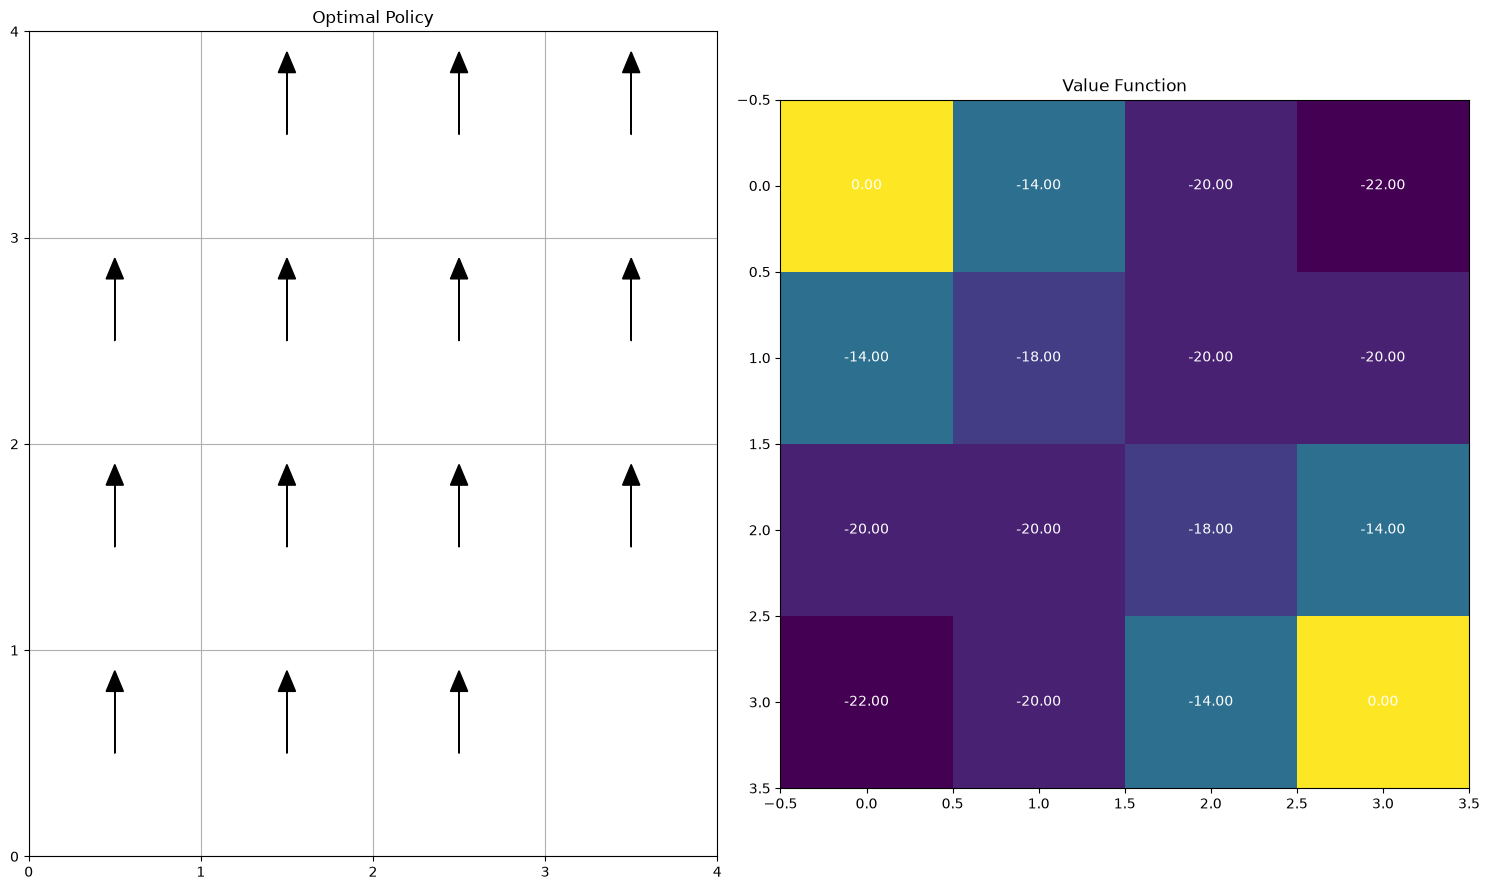

In [125]:
def plot_policy(pi_a_s, v, GRID_SIZE=4, states=grid_4.states, actions=grid_4.actions, P=grid_4.P):
    import matplotlib.pyplot as plt
    import matplotlib.patches as patches

    fig, ax = plt.subplots(1, 2, figsize=(15, 9))
    ax[0].set_xlim(0, GRID_SIZE)
    ax[0].set_ylim(0, GRID_SIZE)
    ax[0].set_xticks(np.arange(GRID_SIZE + 1))
    ax[0].set_yticks(np.arange(GRID_SIZE + 1))
    ax[0].grid()

    for s in range(len(states)):
        if all([P[s][a][1] == 0 for a in actions]):
            continue
        i, j = np.unravel_index(s, (GRID_SIZE, GRID_SIZE))
        best_action = np.argmax(pi_a_s[s])
        if best_action == 0:  # UP
            ax[0].arrow(j + 0.5, GRID_SIZE - i - 0.5, 0, 0.3, head_width=0.1, head_length=0.1, fc='k', ec='k')
        elif best_action == 1:  # RIGHT
            ax[0].arrow(j + 0.5, GRID_SIZE - i - 0.5, 0.3, 0, head_width=0.1, head_length=0.1, fc='k', ec='k')
        elif best_action == 2:  # DOWN
            ax[0].arrow(j + 0.5, GRID_SIZE - i - 0.5, 0, -0.3, head_width=0.1, head_length=0.1, fc='k', ec='k')
        elif best_action == 3:  # LEFT
            ax[0].arrow(j + 0.5, GRID_SIZE - i - 0.5, -0.3, 0, head_width=0.1, head_length=0.1, fc='k', ec='k')

    ax[0].set_title("Optimal Policy")
    ax[1].set_title("Value Function")
    ax[1].imshow(v.reshape(GRID_SIZE, GRID_SIZE), cmap='viridis', interpolation='nearest')
    # annotation for the value function
    for i in range(GRID_SIZE):
        for j in range(GRID_SIZE):
            state = np.ravel_multi_index((i, j), (GRID_SIZE, GRID_SIZE))
            ax[1].text(j, i, f"{v[state]:.2f}", ha='center', va='center', color='white')
            
    plt.tight_layout()
    plt.show()

plot_policy(pi_a_s, v, GRID_SIZE=4, states=grid_4.states, actions=grid_4.actions, P=grid_4.P)

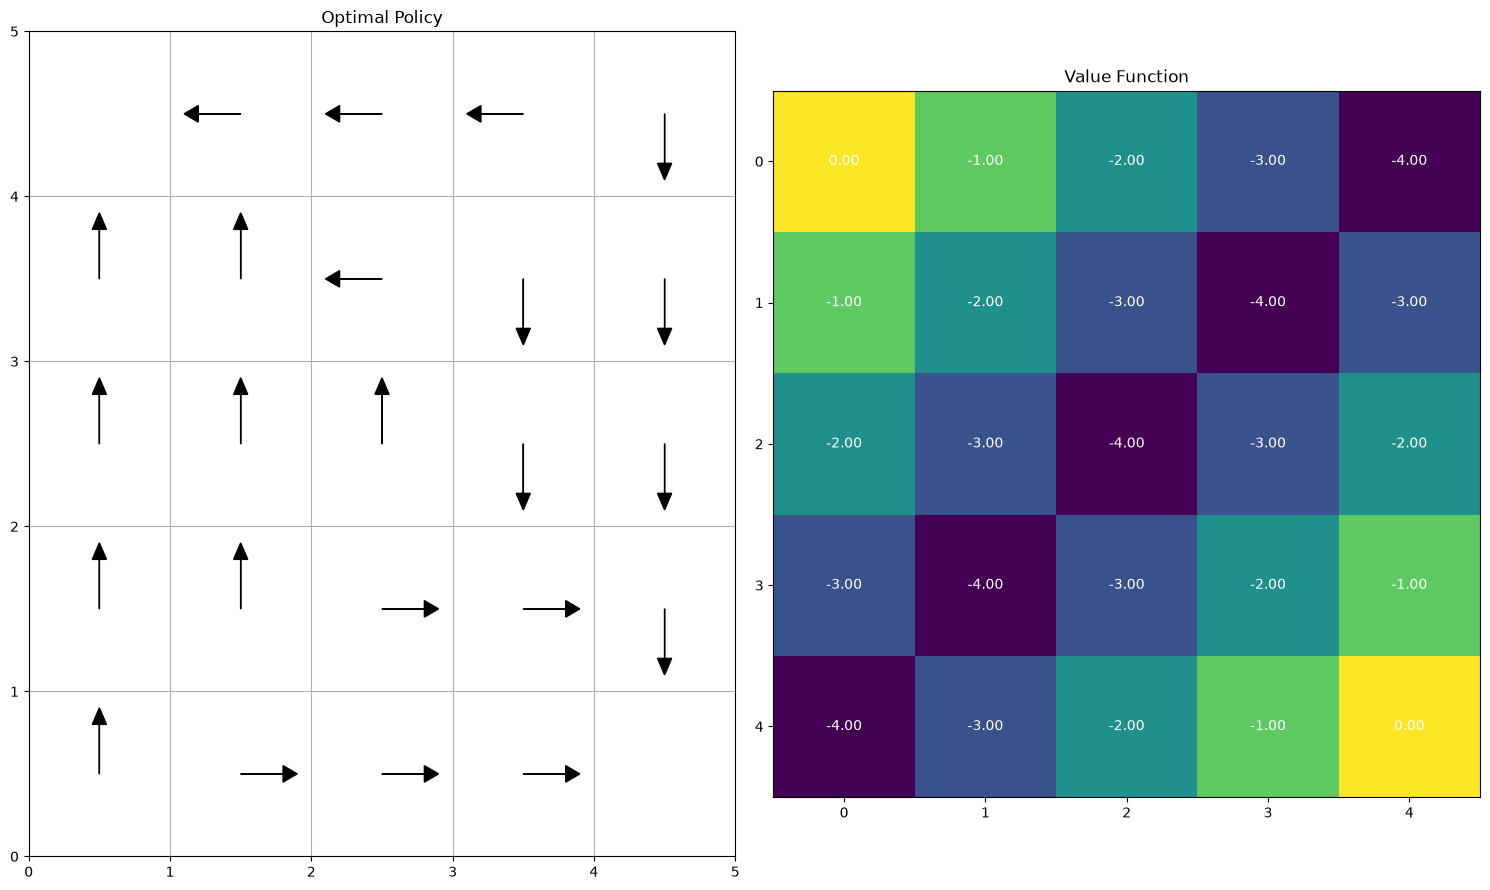

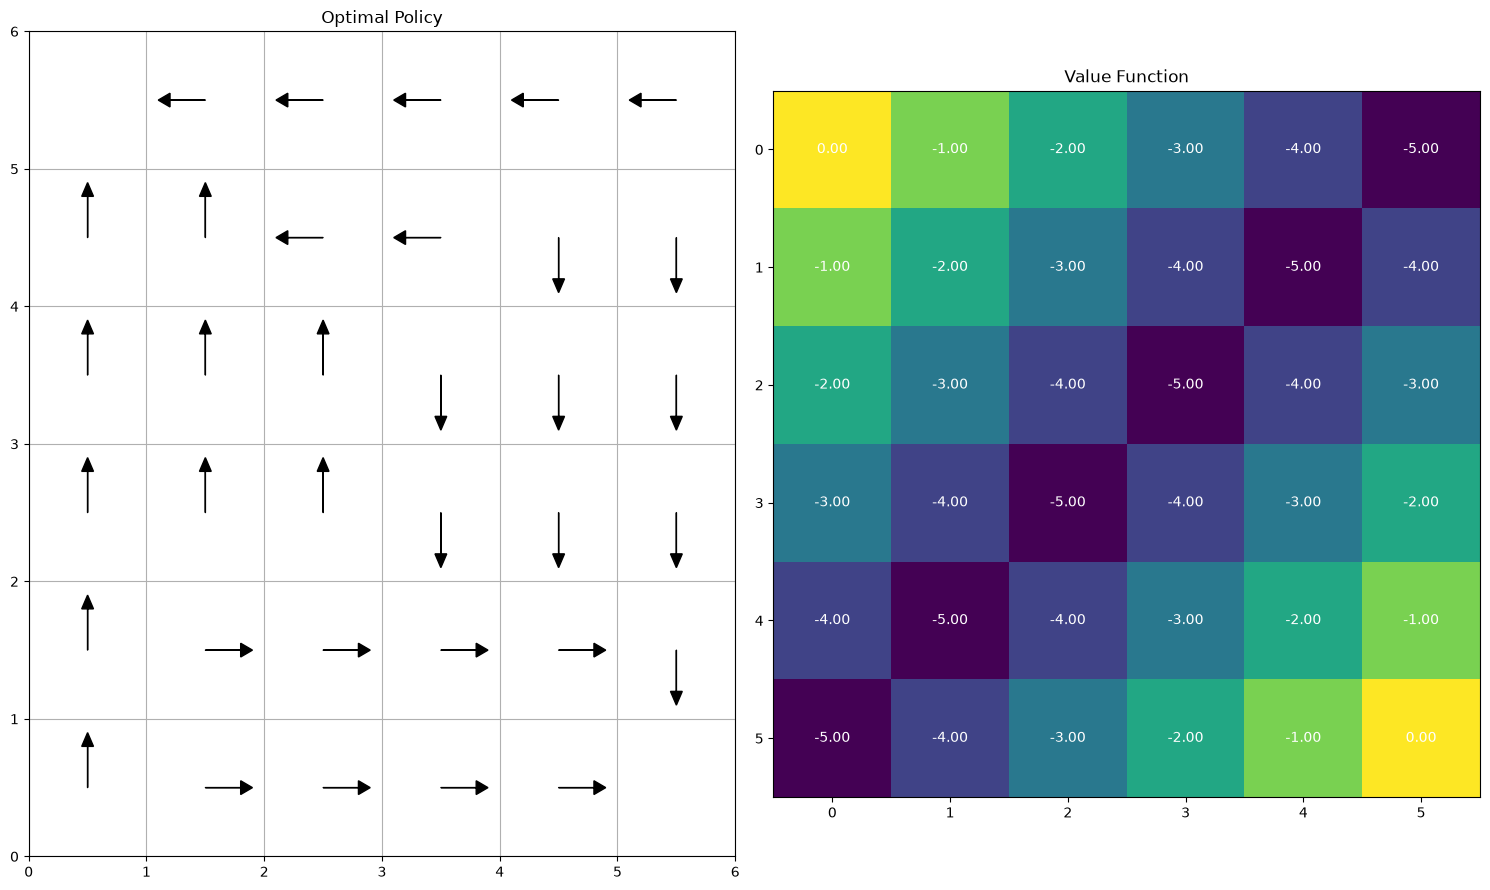

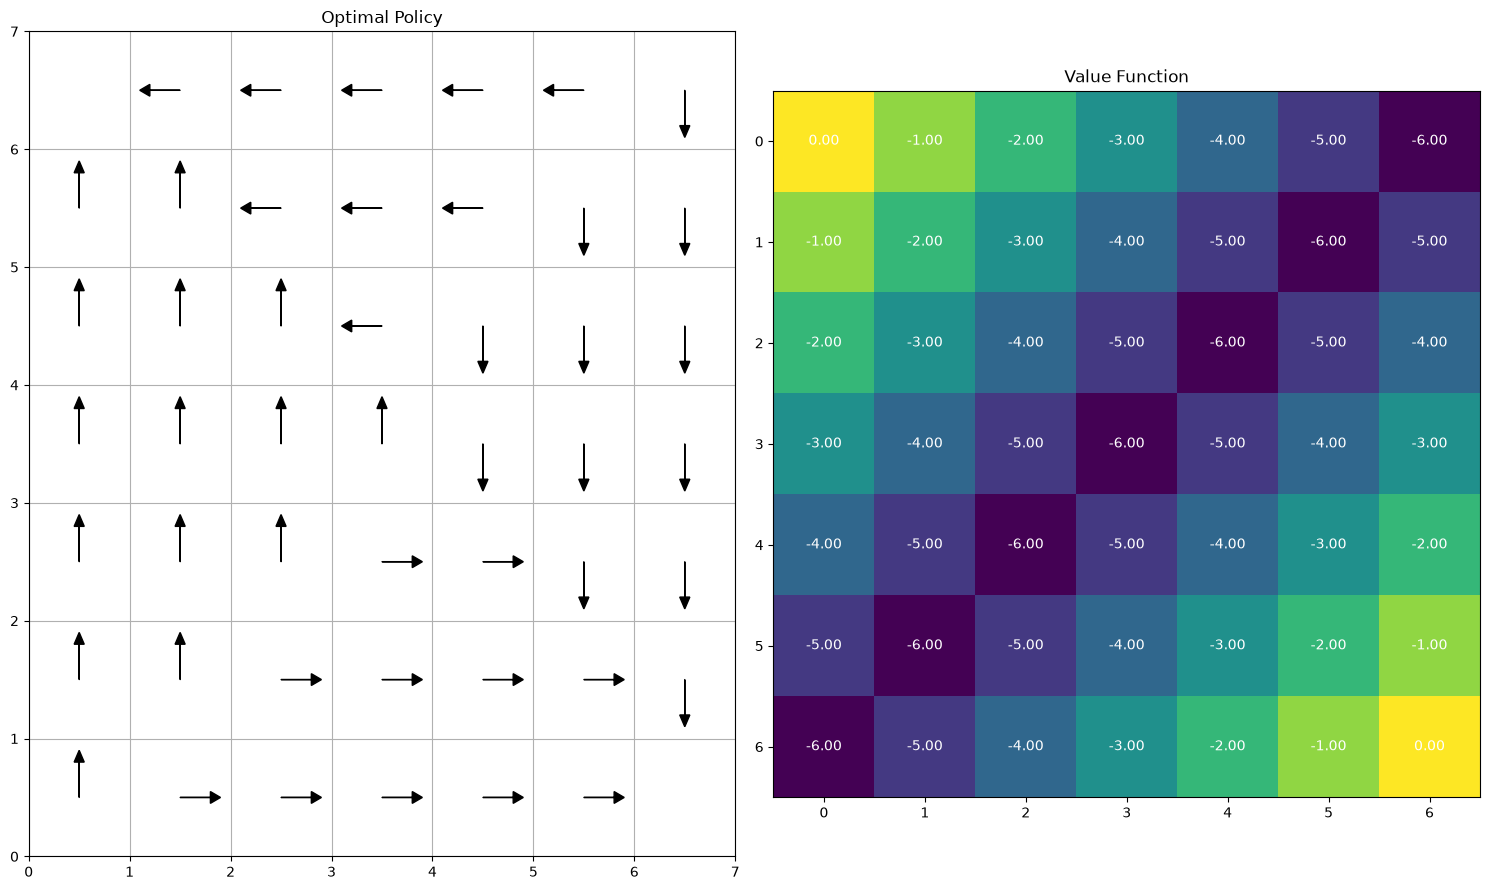

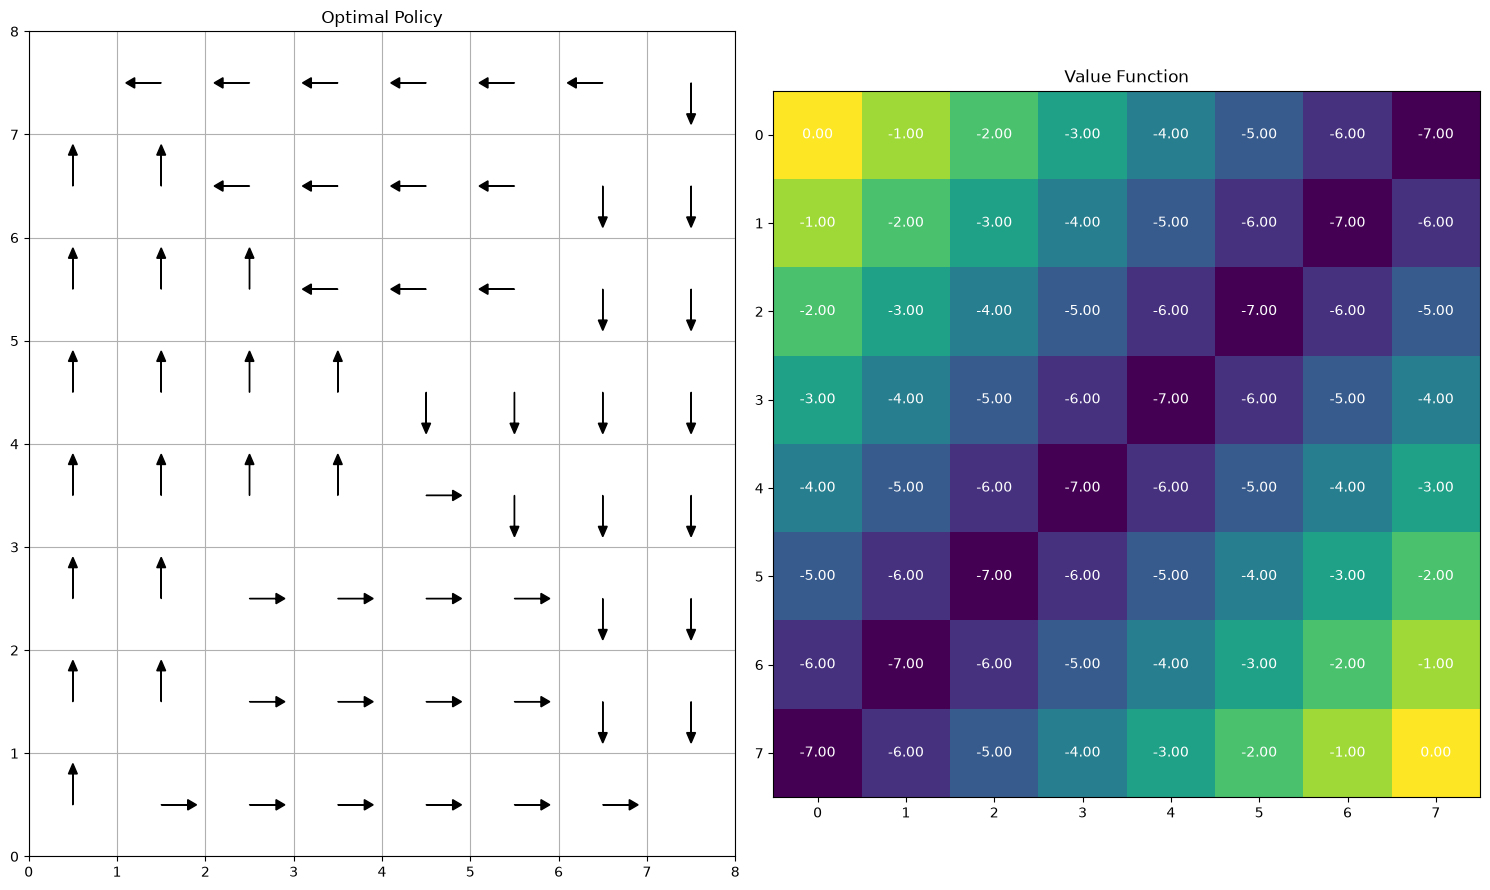

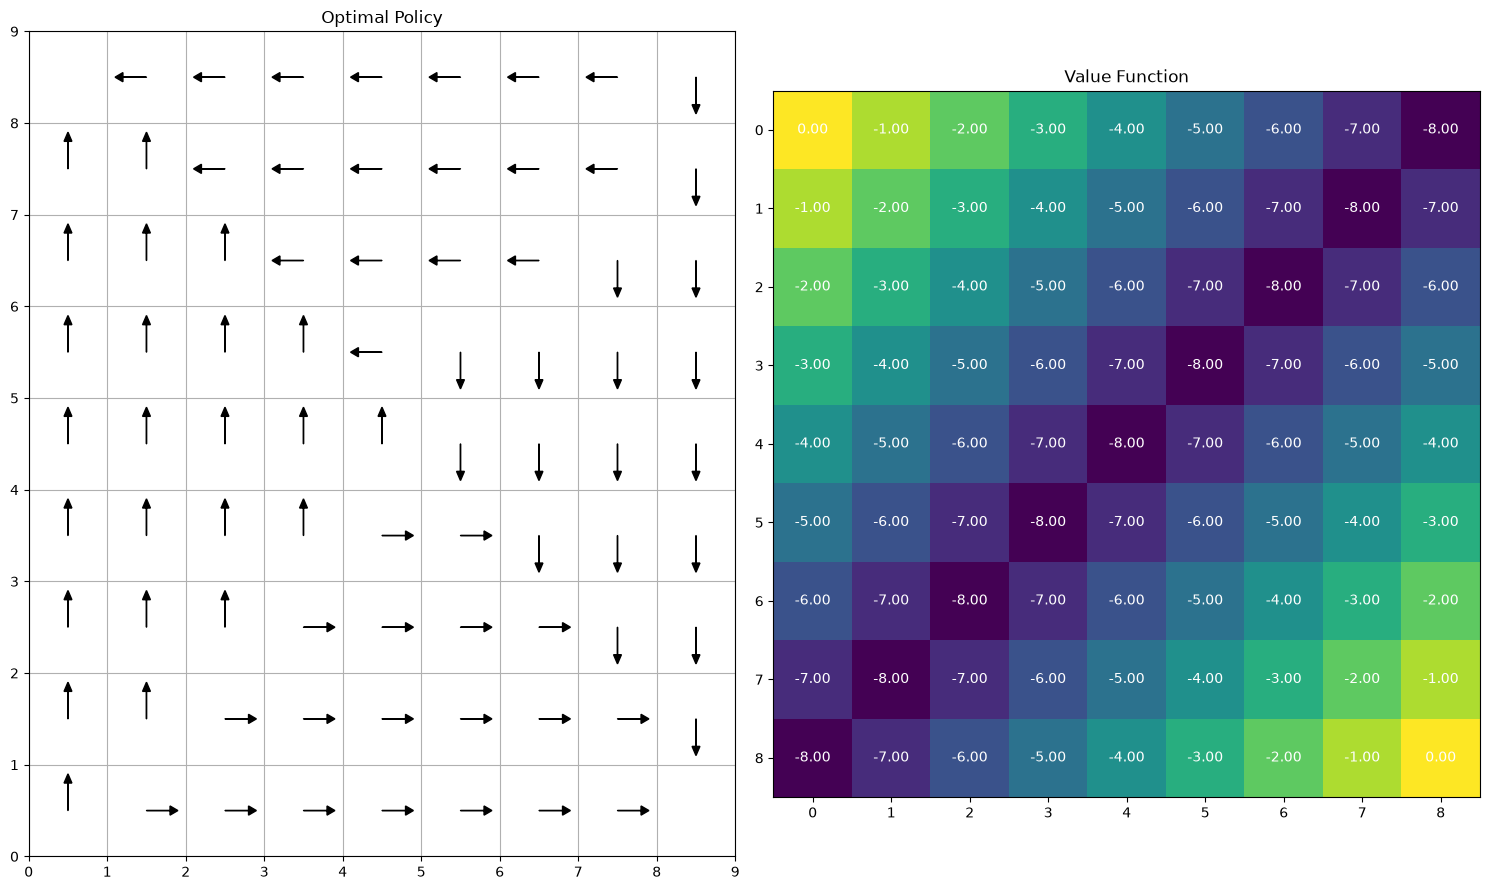

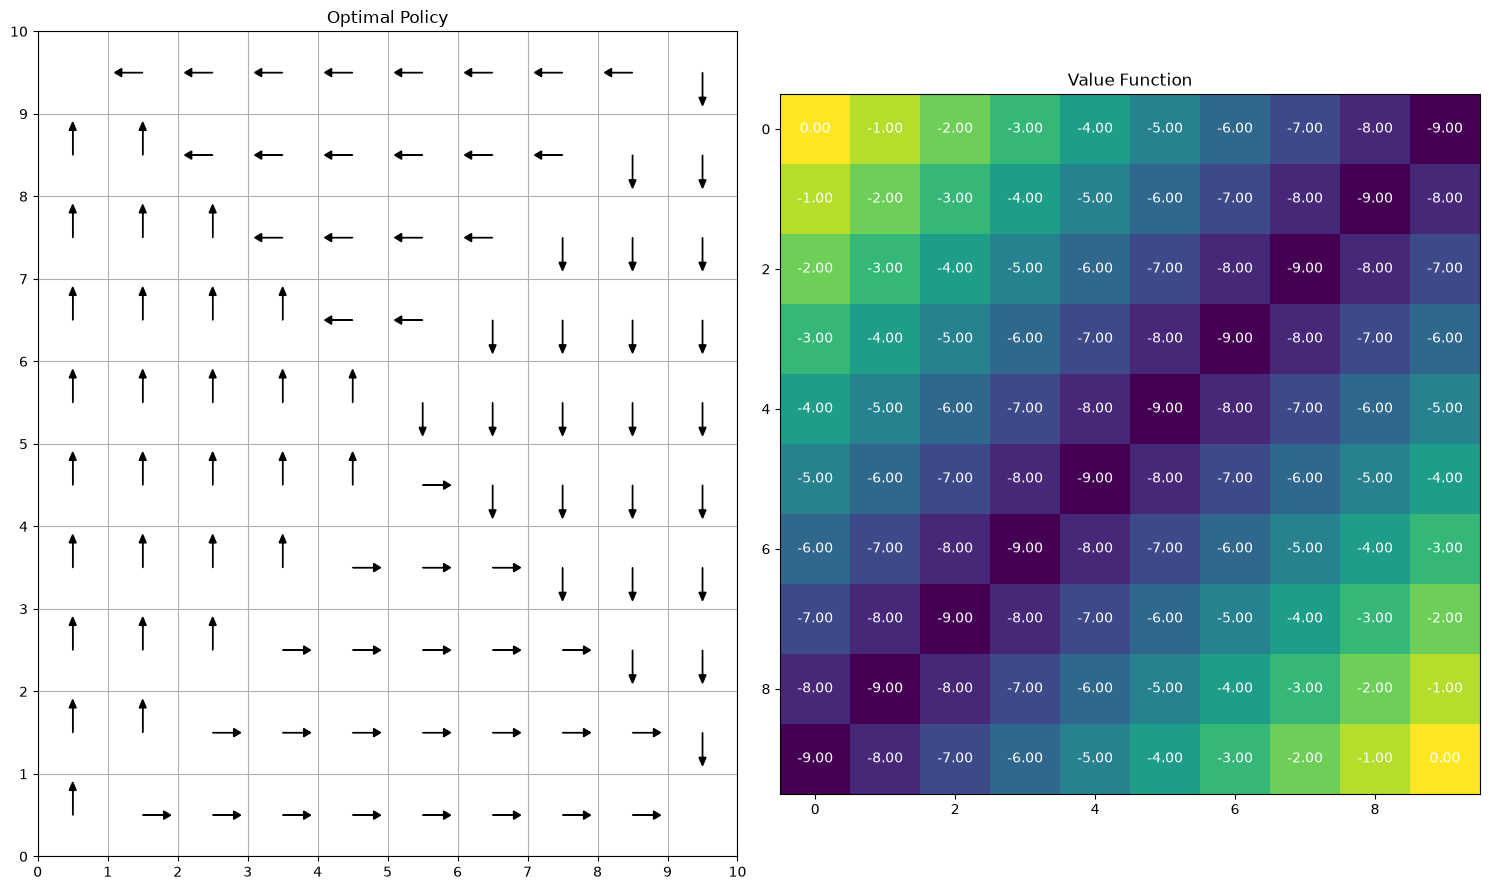

In [126]:

problem_sizes = [5, 6, 7, 8, 9, 10]

problems = [GridWorld(grid_size=size, discount=1., policy=None) for size in problem_sizes]

for problem in problems:
    P_ss = problem.generate_P_s_s(problem.P)
    r_pi = problem.generate_r_pi(problem.P, problem.policy)
    pi_a_s = problem.generate_pi_a_s(problem.P, problem.policy)
    
    v_policy_iter, pi_policy_iter = policy_iteration(P_ss, problem.P, r_pi, pi_a_s, problem.states, problem.actions, discount=1)
    v_value_iter, pi_value_iter = value_iteration(problem.P, problem.states, problem.actions, discount=1)

    plot_policy(pi_policy_iter, v_value_iter, GRID_SIZE=problem.grid_size, states=problem.states, actions=problem.actions, P=problem.P)
   